<a href="https://colab.research.google.com/github/yuhui-0611/Unstructured-Data-Analysis/blob/main/UDA_project_pre_data_eda.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [ ]:
!apt-get -qq install fonts-nanum

import matplotlib.font_manager as fm

# 폰트 캐시 갱신
fm.fontManager.addfont(
    '/usr/share/fonts/truetype/nanum/NanumGothic.ttf'
)

plt.rcParams['font.family'] = 'NanumGothic'
plt.rcParams['axes.unicode_minus'] = False

In [ ]:
meta = pd.read_csv('shorts_metadata_final.csv')
meta.head()

,video_id,url,channel,channel_id,channel_url,channel_follower_count,title,description,tags,title_hashtags,...,days_since_upload,duration_sec,view_count,like_count,comment_count,width,height,vcodec,video_file,drama_name
0,zAaltJrS_rc,https://www.youtube.com/shorts/zAaltJrS_rc,숏까네,UCX2VRPPCDpur-bsj1h1vrrQ,https://www.youtube.com/@%ED%94%BC%EC%B9%B4%EB...,NaN,이거입구 뛰어내리면 안돼!? #뉴토피아 #쿠팡플레이,🖍️본 콘텐츠는 #쿠팡플레이 로부터 제작 허가를 받아 제작하였습니다. 🖍️전체 ...,NaN,뉴토피아|쿠팡플레이,...,588.87,52,2518793,NaN,219.0,360,640,avc1.4D401E,zAaltJrS_rc.mp4,뉴토피아
1,re3q4oBG4Nc,https://www.youtube.com/shorts/re3q4oBG4Nc,숏까네,UCX2VRPPCDpur-bsj1h1vrrQ,https://www.youtube.com/@%ED%94%BC%EC%B9%B4%EB...,NaN,"#드라이브인타이페이 #계륜미 #분노의질주,#말할수없는비밀, #페라리,#서울모터쇼,#...",드라이브 인 타이페이 (2024) Weekend In Taipei 📌주연 : 루크...,NaN,드라이브인타이페이|계륜미|분노의질주|말할수없는비밀|페라리|서울모터쇼|4월영화신작|D...,...,565.79,59,127219,NaN,8.0,360,640,avc1.4D401E,re3q4oBG4Nc.mp4,드라이브 인 타이페이
2,zIjdm3u5CwQ,https://www.youtube.com/shorts/zIjdm3u5CwQ,숏까네,UCX2VRPPCDpur-bsj1h1vrrQ,https://www.youtube.com/@%ED%94%BC%EC%B9%B4%EB...,NaN,무덤방이 존재하는 이유 #광장 #소지섭,"📌넷플릭스 광장📌 스스로 아킬레스 건을 자르고 광장 세계를 떠났던 ‘기준’이, 조직...",NaN,광장|소지섭,...,508.51,59,196398,NaN,10.0,360,640,avc1.4D401E,zIjdm3u5CwQ.mp4,광장
3,A1R9yTf2VIU,https://www.youtube.com/shorts/A1R9yTf2VIU,숏까네,UCX2VRPPCDpur-bsj1h1vrrQ,https://www.youtube.com/@%ED%94%BC%EC%B9%B4%EB...,NaN,이게다야? 내가너희들 부른거야 #넷플릭스 #광장 #소지섭,"📌넷플릭스 광장📌 스스로 아킬레스 건을 자르고 광장 세계를 떠났던 ‘기준’이, 조직...",NaN,넷플릭스|광장|소지섭,...,507.88,54,999929,NaN,22.0,360,640,avc1.4D401E,A1R9yTf2VIU.mp4,광장
4,JEU1zpGfsqQ,https://www.youtube.com/shorts/JEU1zpGfsqQ,숏까네,UCX2VRPPCDpur-bsj1h1vrrQ,https://www.youtube.com/@%ED%94%BC%EC%B9%B4%EB...,NaN,무덤방 시스템이 기가막힌 이유 #넷플릭스 #광장 #소지섭,"📌넷플릭스 광장📌 스스로 아킬레스 건을 자르고 광장 세계를 떠났던 ‘기준’이, 조직...",NaN,넷플릭스|광장|소지섭,...,507.63,58,924796,NaN,66.0,360,640,avc1.4D401E,JEU1zpGfsqQ.mp4,광장


In [ ]:
meta.columns

Index(['video_id', 'url', 'channel', 'channel_id', 'channel_url',
       'channel_follower_count', 'title', 'description', 'tags',
       'title_hashtags', 'desc_hashtags', 'drama_guess', 'uploaded_at',
       'collected_at', 'days_since_upload', 'duration_sec', 'view_count',
       'like_count', 'comment_count', 'width', 'height', 'vcodec',
       'video_file', 'drama_name'],
      dtype='object')

In [ ]:
drama_counts = meta['drama_name'].value_counts()
drama_counts

,count
drama_name,
포핸즈,87
모두가 자신의 무가치함과 싸우고 있다,64
100일의거짓말,63
슬기로운 의사생활,53
다음생은 없으니까,46
언젠가는 슬기로울 전공의생활,27
광장,25
아파트,25
지금 불륜이 문제가 아닙니다,24


In [ ]:
meta["drama_name"].nunique()

55

## 결측

In [ ]:
meta.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 635 entries, 0 to 634
Data columns (total 24 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   video_id                635 non-null    object 
 1   url                     635 non-null    object 
 2   channel                 635 non-null    object 
 3   channel_id              635 non-null    object 
 4   channel_url             635 non-null    object 
 5   channel_follower_count  0 non-null      float64
 6   title                   635 non-null    object 
 7   description             542 non-null    object 
 8   tags                    1 non-null      object 
 9   title_hashtags          582 non-null    object 
 10  desc_hashtags           500 non-null    object 
 11  drama_guess             635 non-null    object 
 12  uploaded_at             635 non-null    object 
 13  collected_at            635 non-null    object 
 14  days_since_upload       635 non-null    fl

In [ ]:
# 결측치가 하나라도 있는 열만 추출
missing_cols = meta.columns[meta.isna().any()]

# 해당 열들로 새로운 DataFrame 생성
meta_missing = meta[missing_cols].copy()

display(meta_missing)

,channel_follower_count,description,tags,title_hashtags,desc_hashtags,like_count,comment_count
0,NaN,🖍️본 콘텐츠는 #쿠팡플레이 로부터 제작 허가를 받아 제작하였습니다. 🖍️전체 ...,NaN,뉴토피아|쿠팡플레이,쿠팡플레이|박정민|지수|임성재|김준한|강영석,NaN,219.0
1,NaN,드라이브 인 타이페이 (2024) Weekend In Taipei 📌주연 : 루크...,NaN,드라이브인타이페이|계륜미|분노의질주|말할수없는비밀|페라리|서울모터쇼|4월영화신작|D...,NaN,NaN,8.0
2,NaN,"📌넷플릭스 광장📌 스스로 아킬레스 건을 자르고 광장 세계를 떠났던 ‘기준’이, 조직...",NaN,광장|소지섭,넷플릭스에,NaN,10.0
3,NaN,"📌넷플릭스 광장📌 스스로 아킬레스 건을 자르고 광장 세계를 떠났던 ‘기준’이, 조직...",NaN,넷플릭스|광장|소지섭,넷플릭스에,NaN,22.0
4,NaN,"📌넷플릭스 광장📌 스스로 아킬레스 건을 자르고 광장 세계를 떠났던 ‘기준’이, 조직...",NaN,넷플릭스|광장|소지섭,넷플릭스에,NaN,66.0
...,...,...,...,...,...,...,...
630,NaN,부모의 문제로 자식이 파혼 당한 이유는? ##슬기로운의사생활 #슬의생 #언젠가는슬기...,NaN,슬기로운의사생활|슬의생|언젠가는슬기로울전공의생활|언슬전|조정석|유연석|안은진|정경호...,슬기로운의사생활|슬의생|언젠가는슬기로울전공의생활|언슬전|조정석|유연석|안은진|정경호...,NaN,522.0
631,NaN,찐남매로 40년 살면서 처음으로 느껴본 마음 #슬기로운의사생활 #슬의생 #언젠가는슬...,NaN,슬기로운의사생활|슬의생|언젠가는슬기로울전공의생활|언슬전|조정석|유연석|안은진|정경호,슬기로운의사생활|슬의생|언젠가는슬기로울전공의생활|언슬전|조정석|유연석|안은진|정경호...,NaN,258.0
632,NaN,엇갈린 시간 속에 지켜왔던 오랜 고백 #슬기로운의사생활 #슬의생 #언젠가는슬기로울전...,NaN,슬기로운의사생활|슬의생|언젠가는슬기로울전공의생활|언슬전|조정석|유연석|안은진|정경호...,슬기로운의사생활|슬의생|언젠가는슬기로울전공의생활|언슬전|조정석|유연석|안은진|정경호...,NaN,287.0
633,NaN,첫 출근 첫 모습에 반한 짝사랑을 기억하는 방법 #슬기로운의사생활 #슬의생 #언젠가...,NaN,슬기로운의사생활|슬의생|언젠가는슬기로울전공의생활|언슬전|조정석|유연석|안은진|정경호...,슬기로운의사생활|슬의생|언젠가는슬기로울전공의생활|언슬전|조정석|유연석|안은진|정경호...,NaN,79.0


In [ ]:
missing_cols

Index(['channel_follower_count', 'description', 'tags', 'title_hashtags',
       'desc_hashtags', 'like_count', 'comment_count'],
      dtype='object')

- 나중에 YouTube API로 조회수, 좋아요, 댓글 수를 동일 시점에 재수집할 계획이라서 일단 결측은 깊이있게 안봐도 될 듯

## 10개 이상인 drama => eda_10

In [ ]:
eda = meta.copy()

In [ ]:
# 10개 이상인 드라마만 추출
drama_counts = eda['drama_name'].value_counts()
valid_dramas = drama_counts[drama_counts >= 10].index

eda_10 = eda[
    eda['drama_name'].isin(valid_dramas)
].copy()

eda_10 = eda_10.reset_index(drop=True)

print("원본 영상 수:", len(eda))
print("원본 드라마 수:", eda['drama_name'].nunique())

print("분석 대상 영상 수:", len(eda_10))
print("분석 대상 드라마 수:", eda_10['drama_name'].nunique())

원본 영상 수: 635
원본 드라마 수: 55
분석 대상 영상 수: 505
분석 대상 드라마 수: 16


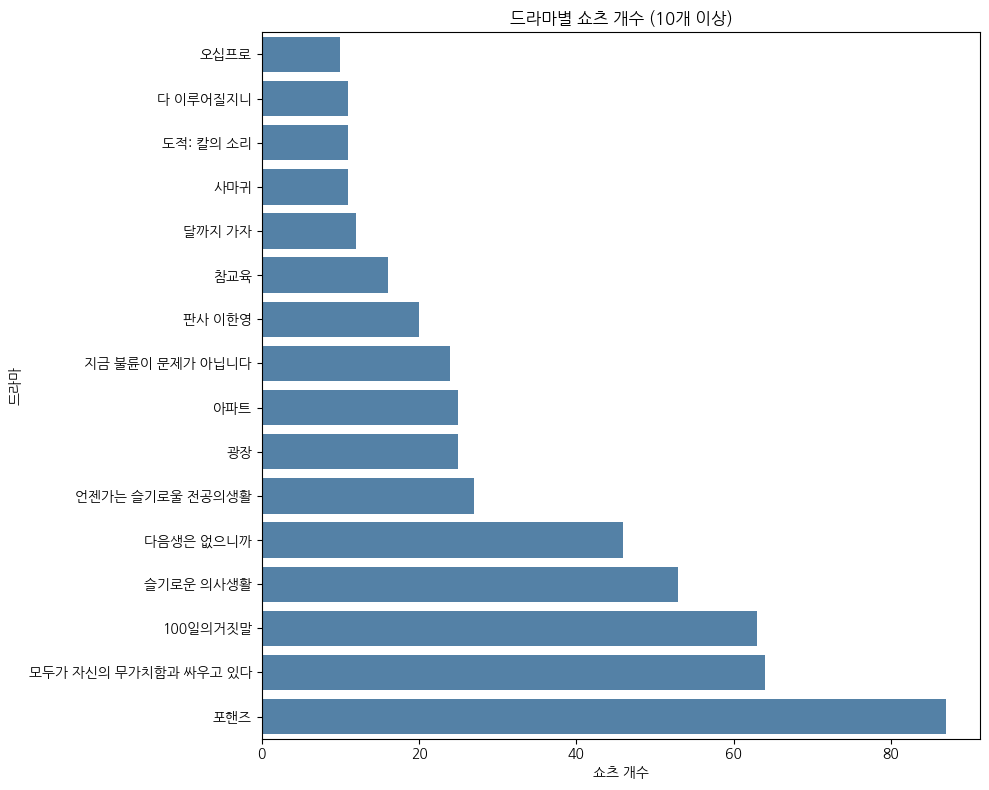

In [ ]:
drama_counts_10 = (
    eda_10['drama_name']
    .value_counts()
    .sort_values(ascending=True)
)

plt.figure(figsize=(10, 8))

sns.barplot(
    x=drama_counts_10.values,
    y=drama_counts_10.index,
    color='steelblue'
)

plt.xlabel('쇼츠 개수')
plt.ylabel('드라마')
plt.title('드라마별 쇼츠 개수 (10개 이상)')
plt.tight_layout()
plt.show()

## 조회수 분포 - API 수집 전

In [ ]:
eda_10['view_count'].describe().apply(lambda x: f'{x:,.0f}')

,view_count
count,505
mean,"825,409"
std,"1,603,654"
min,84
25%,"72,819"
50%,"239,264"
75%,"751,990"
max,"15,198,332"


- 평균 약 83만 회, 중앙값 약 24만 회
- 평균이 중앙값보다 큼
- 최댓값은 약 1,520만 회로 일부 영상에 높은 조회수가 집중된 오른쪽 꼬리가 긴 분포
- 로그 변환 전후의 분포 비교해야함

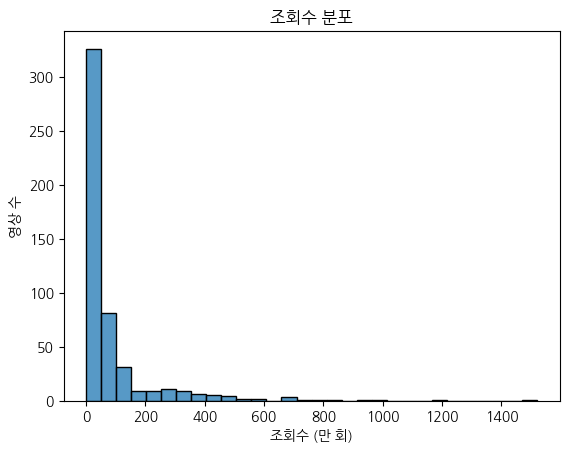

In [ ]:
sns.histplot(eda_10['view_count'] / 10000, bins=30)

plt.xlabel('조회수 (만 회)')
plt.ylabel('영상 수')
plt.title('조회수 분포')
plt.show()

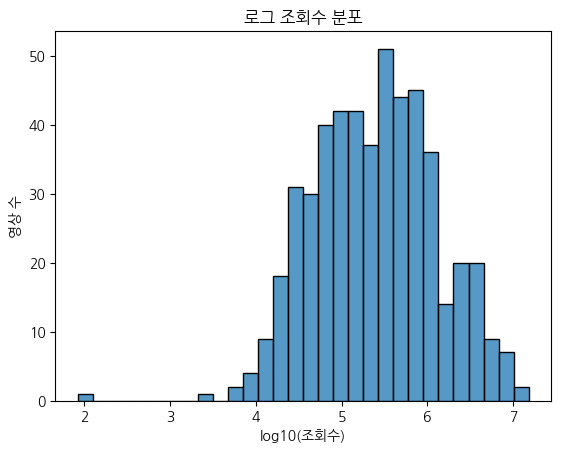

In [ ]:
sns.histplot(np.log10(eda_10['view_count'].clip(lower=1)), bins=30)
plt.xlabel('log10(조회수)')
plt.ylabel('영상 수')
plt.title('로그 조회수 분포')
plt.show()

- 대다수 영상은 로그 조회수 약 4.5~6.2 구간에 분포
- 일부 조회수가 매우 낮은 영상은 왼쪽 꼬리 부분에 존재
- 로그 변환해야함
> 극단값과의 편차 완화

### 드라마별 조회수 차이

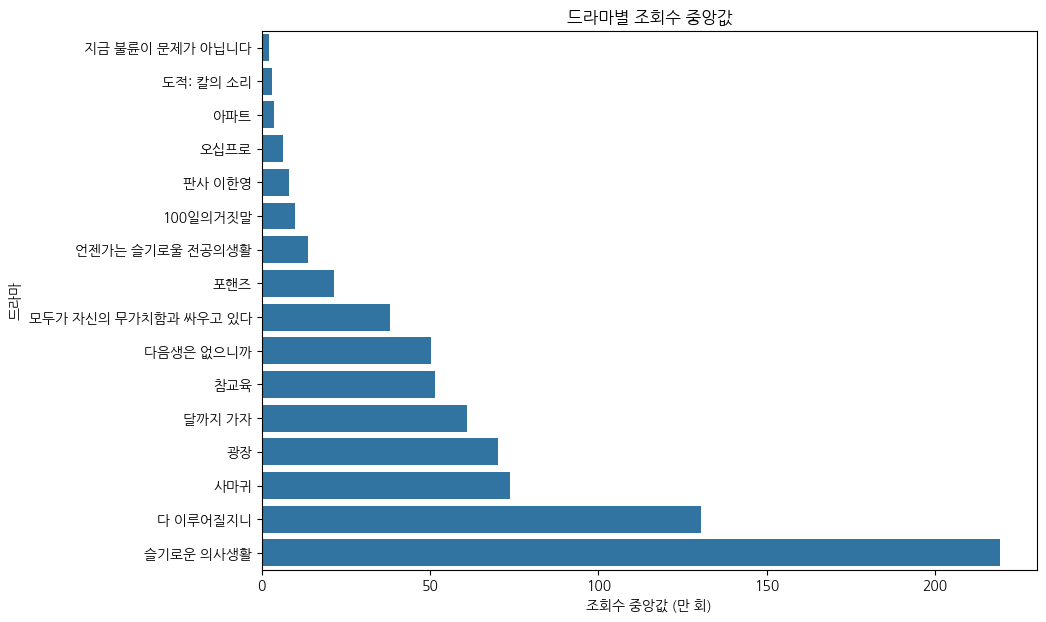

In [ ]:
drama_views = eda_10.groupby('drama_name')['view_count'].median().sort_values()

plt.figure(figsize=(10, 7))
sns.barplot(x=drama_views.values / 10000, y=drama_views.index)

plt.xlabel('조회수 중앙값 (만 회)')
plt.ylabel('드라마')
plt.title('드라마별 조회수 중앙값')
plt.show()

- 드라마별 조회수 중앙값에 큰 차이가 존재
- 일부 드라마는 조회수 중앙값이 100만 회를 넘지만, 다른 드라마는 수만 회
- 작품에 따라 조회수 수준이 크게 다름
> 같은 드라마에서 나온 쇼츠들끼리 비교하는 **드라마 내 상대적 성과**를 사용해야 함

In [ ]:
from sklearn.metrics import r2_score

df = eda_10.copy()
df['log_views'] = np.log10(df['view_count'].clip(lower=1))

drama_mean = df.groupby('drama_name')['log_views'].transform('mean')

r2 = r2_score(df['log_views'], drama_mean)

print(f"드라마별 설명력 R²: {r2:.3f} ({r2*100:.1f}%)")

드라마별 설명력 R²: 0.431 (43.1%)


- 조회수가 똑같아도 어떤 드라마에 속해 있는지에 따라 성과의 의미가 달라짐
- 전체 쇼츠의 로그 조회수 차이 중 약 43.1%가 드라마별 평균 조회수 차이로 설명된다는 뜻
- 즉, 쇼츠의 조회수가 개별 영상의 특성뿐 아니라 어떤 드라마에 속하는지와도 상당한 연관성을 가진다는 의미
> 드라마 내 상대적 성과를 사용해야 함이 다시 입증됨

**< z_in_drama >**

1. 조회수 로그 변환
2. 업로드 경과일 보정
3. 같은 드라마 내 z-score 계산
> z = (보정 조회수 - 보정 조회수 평균) / 보정 조회수 표준편차

### 업로드 경과일과 조회수의 관계

In [ ]:
eda_10['days_since_upload'].describe()

,days_since_upload
count,505.000000
mean,143.098851
std,145.616274
min,0.000000
25%,28.020000
50%,73.730000
75%,187.640000
max,508.510000


- 경과일이 0인 영상도 있으므로, 프로젝트의 14일 미만 영상 제외해야함

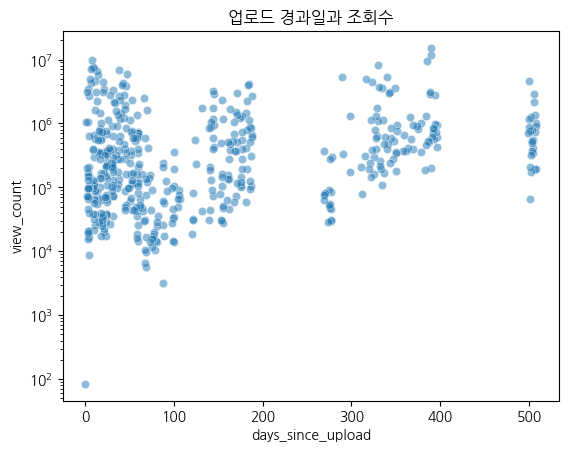

In [ ]:
sns.scatterplot(
    data=eda_10,
    x='days_since_upload',
    y='view_count',
    alpha=0.5
)

plt.yscale('log')  # 조회수 편차가 커서 로그 스케일 적용
plt.title('업로드 경과일과 조회수')
plt.show()

## 영상 길이

In [ ]:
eda_10['duration_sec'].describe()

,duration_sec
count,505.000000
mean,56.697030
std,26.471482
min,23.000000
25%,44.000000
50%,50.000000
75%,58.000000
max,179.000000


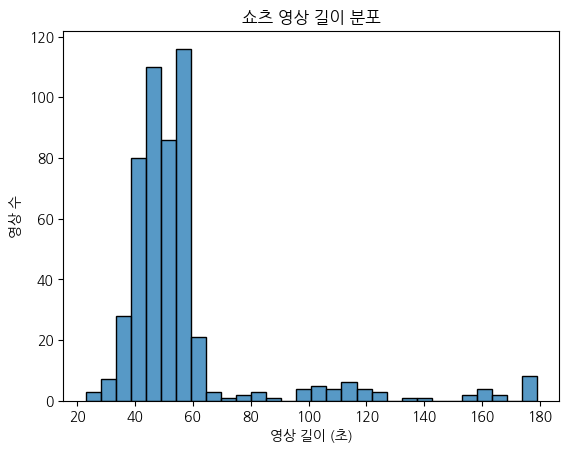

In [ ]:
sns.histplot(eda_10['duration_sec'], bins=30)
plt.xlabel('영상 길이 (초)')
plt.ylabel('영상 수')
plt.title('쇼츠 영상 길이 분포')
plt.show()

In [ ]:
mask = eda_10['duration_sec'].between(30, 60)

print(f"30~60초 영상: {mask.sum()}개")
print(f"비율: {mask.mean()*100:.1f}%")

30~60초 영상: 446개
비율: 88.3%


- 대부분의 영상이 40~60초 사이에 집중
- 중앙값은 50초로, 전형적인 쇼츠 길이가 약 50초임
- 90초 이상의 긴 영상도 일부 존재
- **모델 학습할 때 긴 영상 포함할지 말지 검토**
> 최종 데모에서 계획한 30~60초 슬라이딩 윈도우 설정은 현재 학습 데이터의 길이 특성과 대체로 일치

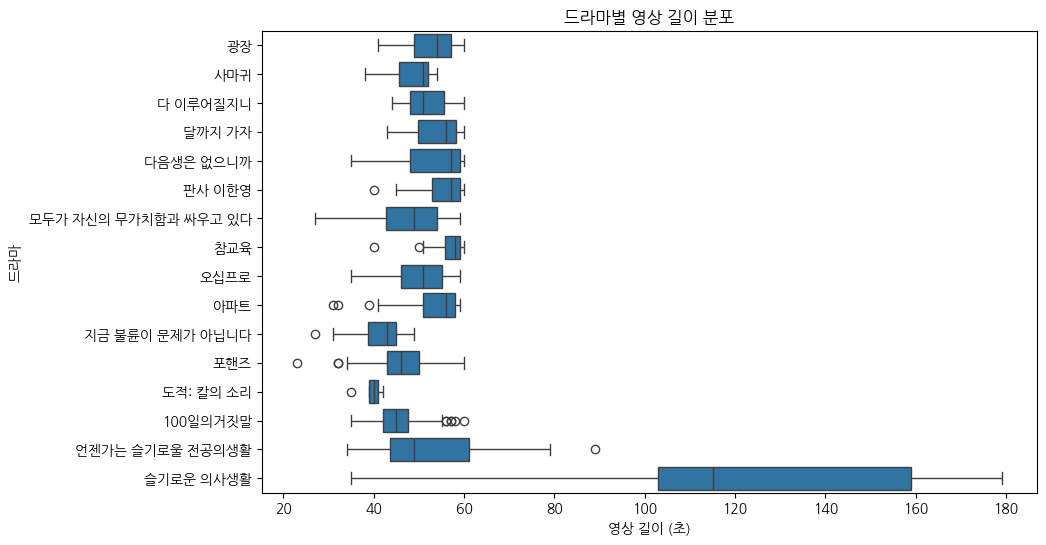

In [ ]:
# 특정 드라마에 긴 영상이 몰려 있는지 확인
plt.figure(figsize=(10, 6))
sns.boxplot(data=eda_10, x='duration_sec', y='drama_name')

plt.xlabel('영상 길이 (초)')
plt.ylabel('드라마')
plt.title('드라마별 영상 길이 분포')
plt.show()

- 슬기로운 의사생활
  - 다른 드라마보다 영상 길이가 전반적으로 긴데..?
  - 분산도 길다..
- 특징 추출 시 영상 길이에 따른 영향 고려해야할듯
> 60초 초과 영상의 포함 여부는 모델 학습과 데모 구간 길이를 고려해 결정

## 중복

In [ ]:
# 중복 ID 확인
eda[eda['video_id'].duplicated(keep=False)]

,video_id,url,channel,channel_id,channel_url,channel_follower_count,title,description,tags,title_hashtags,...,days_since_upload,duration_sec,view_count,like_count,comment_count,width,height,vcodec,video_file,drama_name


In [ ]:
# 중복 ID별 개수
eda['video_id'].value_counts().loc[lambda x: x > 1]

,count
video_id,


- ID 형식이 이상해서 다시 복구함

In [ ]:
eda_fixed = eda.copy()

mask = eda_fixed['video_id'] == '#NAME?'

eda_fixed.loc[mask, 'video_id'] = (
    eda_fixed.loc[mask, 'url']
    .str.extract(r'(?:shorts/|v=|youtu\.be/)([A-Za-z0-9_-]{11})')[0]
    .values
)

In [ ]:
print("복구 실패:", eda_fixed['video_id'].isna().sum())
print("중복 ID:", eda_fixed['video_id'].duplicated().sum())

eda_fixed.loc[mask, ['video_id', 'url']]

복구 실패: 0
중복 ID: 0


,video_id,url


In [ ]:
# 복구된 ID를 원래 데이터에 반영
meta['video_id'] = eda_fixed['video_id'].copy()

# EDA 데이터에도 반영
eda = meta.copy()

# 기존 CSV 덮어쓰기
meta.to_csv('shorts_metadata_final.csv', index=False, encoding='utf-8-sig')

In [ ]:
print("비정상 ID:", (~meta['video_id'].str.fullmatch(r'[A-Za-z0-9_-]{11}')).sum())
print("중복 ID:", meta['video_id'].duplicated().sum())

비정상 ID: 0
중복 ID: 0


In [ ]:
meta[meta['video_id'].str.startswith('-', na=False)][['video_id', 'url']].head(10)

,video_id,url
21,--dCeRvCHTw,https://www.youtube.com/shorts/--dCeRvCHTw
76,-xLHaqSzasI,https://www.youtube.com/shorts/-xLHaqSzasI
207,-i2OI0zw73Y,https://www.youtube.com/shorts/-i2OI0zw73Y
214,-ZTAInbsy7I,https://www.youtube.com/shorts/-ZTAInbsy7I
268,-PXTwRGamIE,https://www.youtube.com/shorts/-PXTwRGamIE
334,-ZDH8FZ4vXk,https://www.youtube.com/shorts/-ZDH8FZ4vXk
361,-D3_hyil_OY,https://www.youtube.com/shorts/-D3_hyil_OY
492,-NlldWwOqcw,https://www.youtube.com/shorts/-NlldWwOqcw
584,-DQdT6DV92Y,https://www.youtube.com/shorts/-DQdT6DV92Y
601,-NJrGeC5gac,https://www.youtube.com/shorts/-NJrGeC5gac


길이, 채널과의 차이, 업로드 경과일

데이터 합치고 API로 수집 - 1명

전처리 겸 eda - 2명 → 전처리 하면서 데이터 구성 보기, 여러가지 preprocessed csv 만들기

베이스라인 모델 실험 결과 비교 - 3명 다